# An End-to-End Data Science and Classical Machine Learning Pipeline for Robotic Slip Detection Using Fingertip IMU Data

**Course**: Semester 5 Introduction to Data Science  
**Dataset**: SLID-CH (*Slip Labels and Inertial Data from Compliant Hand*)  
**Reference Paper**: *Slip detection for compliant robotic hands using inertial signals and deep learning* (Cravetta et al., *Frontiers in Robotics and AI*, 2025)  
**Evaluated Models**: Logistic Regression, K-Nearest Neighbors (KNN), Random Forest, LightGBM

---

## 1. Introduction, Problem Statement, and Objectives

### 1.1 The Robotics Problem: Tactile Slip Detection
In autonomous robotic manipulation with compliant or tendon-driven robotic hands, maintaining a stable grasp without crushing fragile objects requires real-time slip detection. When grasping unknown or deformable items, unexpected external disturbances or insufficient grip force lead to micro-slips at the fingertip-object interface. Detecting incipient slip with low latency allows robotic controllers to dynamically adjust grip forces before an object is dropped.

### 1.2 Why Fingertip IMU Sensors?
Vision-based tactile sensors often suffer from occlusions, mechanical fragility, and high computational latency. In contrast, 6-axis **Inertial Measurement Units (IMUs)** embedded inside compliant fingertips capture high-frequency microscopic vibrations, shear accelerations, and rotational jerks directly at the contact interface. These inertial signals provide an information-rich, computationally lightweight data source.

### 1.3 Core Project Focus & Machine Learning Scope
This semester project demonstrates a complete, transparent **Data Science and Classical Machine Learning workflow**:
$$\text{Raw Telemetry} \longrightarrow \text{Quality Audit} \longrightarrow \text{Preprocessing} \longrightarrow \text{Labeling} \longrightarrow \text{Windowing} \longrightarrow \text{Feature Engineering} \longrightarrow \text{EDA} \longrightarrow \text{Model Training} \longrightarrow \text{Evaluation} \longrightarrow \text{Interpretability}$$

We train and evaluate **four classical machine learning algorithms**:
1. **Logistic Regression**: Interpretable linear classification baseline.
2. **K-Nearest Neighbors (KNN)**: Non-parametric, distance-based classification.
3. **Random Forest**: Non-linear bagging ensemble capable of modeling feature interactions.
4. **LightGBM**: Highly optimized gradient-boosted decision trees.

### 1.4 Secondary Investigation: Contextual Object Identity (Approaches A vs. C)
As a secondary investigation into feature representation, we evaluate each algorithm under two input configurations:
- **Approach A (General Baseline)**: 84 statistical features derived purely from the 12 IMU channels.
- **Approach C (Object-Aware)**: The same 84 IMU features plus one-hot encoded object identity tags (89 features total).

This tests how contextual object information alters classification boundaries across different model families.


In [1]:
# Section 1.5: Environment Setup & Library Initialization
%matplotlib inline
import os
import sys
import time
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display, Markdown
except ImportError:
    display = print

# Set consistent plotting aesthetic
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

# Define project directories and file paths
BASE_DIR = r"C:\Vishal\Datascience"
RAW_TRIALS_ROOT = os.path.join(BASE_DIR, "IMUSlip", "IMUSlip", "data", "0-Trials")
RAW_CSV_PATH = os.path.join(BASE_DIR, "slid_ch_raw_all_195_trials.csv")
CLEAN_CSV_PATH = os.path.join(BASE_DIR, "slid_ch_cleaned_features.csv")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "confusion_matrices"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "feature_importance"), exist_ok=True)

print("Environment initialized successfully.")
print("Output directory ready at:", OUTPUT_DIR)


Environment initialized successfully.
Output directory ready at: C:\Vishal\Datascience\outputs


---
## 2. Dataset Loading and Inventory

The original SLID-CH dataset contains **195 physical manipulation trials** recorded across **5 daily objects** of diverse geometries, stiffness, and surface textures:
- *Plastic Cup* (pliable, smooth)
- *Pringles Can* (cylindrical, ultra-smooth low-friction surface)
- *Pudding Box* (prismatic, compliant cardboard)
- *Rubix Cube* (rigid, high-friction rubber/plastic facets)
- *Soup Can* (rigid, metallic cylinder)

Each trial is stored as a set of pickle files (`times.pkl`, `IMU_data.pkl`, `smoothed_contact_sliding_velocities.pkl`).

> **Engineering Note on Data Caching**: To ensure fast execution while maintaining transparency, the cell below inspects the raw trial directory tree to assemble the dataset inventory, while downstream tabular operations utilize the compiled raw telemetry table `slid_ch_raw_all_195_trials.csv`.


In [2]:
# Section 2: Enumerate original trial directories and compile dataset inventory
import pickle

def load_and_inventory_dataset():
    if not os.path.exists(RAW_TRIALS_ROOT):
        print(f"Warning: Raw directory {RAW_TRIALS_ROOT} not found. Falling back to pre-compiled CSV...")
        df_raw = pd.read_csv(RAW_CSV_PATH)
        inv = df_raw.groupby("object")["trial_id"].nunique().reset_index()
        inv.columns = ["Object", "Trials"]
        inv["Total Samples"] = df_raw.groupby("object")["time"].count().values
        inv["IMU Channels"] = 12
        inv["Contact Points"] = 6
        return inv, df_raw.head(5)

    objects = sorted([d for d in os.listdir(RAW_TRIALS_ROOT) if os.path.isdir(os.path.join(RAW_TRIALS_ROOT, d))])
    inventory_rows = []
    total_timesteps = 0

    for obj in objects:
        obj_dir = os.path.join(RAW_TRIALS_ROOT, obj)
        trials = sorted([t for t in os.listdir(obj_dir) if os.path.isdir(os.path.join(obj_dir, t))])
        obj_samples = 0
        
        for t_name in trials:
            t_path = os.path.join(obj_dir, t_name)
            time_file = os.path.join(t_path, "times.pkl")
            if os.path.exists(time_file):
                with open(time_file, "rb") as f:
                    td = pickle.load(f)
                    obj_samples += len(td.get("time", []))
                    
        inventory_rows.append({
            "Object": obj,
            "Trials": len(trials),
            "Samples": obj_samples,
            "IMU Channels": 12,
            "Contact Points": 6
        })
        total_timesteps += obj_samples

    df_inv = pd.DataFrame(inventory_rows)
    
    # Load representative raw trial telemetry for display
    sample_trial = os.path.join(RAW_TRIALS_ROOT, "Plastic Cup", "plastic_cup_A-3-6-1")
    with open(os.path.join(sample_trial, "times.pkl"), "rb") as f:
        t_data = pickle.load(f)
    with open(os.path.join(sample_trial, "IMU_data.pkl"), "rb") as f:
        imu_data = pickle.load(f)

    rep_df = pd.DataFrame({
        "time": t_data["time"][:5],
        "left_ax": imu_data["Left IMU Signal"]["ax"][:5],
        "left_ay": imu_data["Left IMU Signal"]["ay"][:5],
        "left_az": imu_data["Left IMU Signal"]["az"][:5],
        "right_ax": imu_data["Right IMU Signal"]["ax"][:5],
        "right_ay": imu_data["Right IMU Signal"]["ay"][:5],
        "right_az": imu_data["Right IMU Signal"]["az"][:5],
    })
    
    return df_inv, rep_df

df_inv, rep_records = load_and_inventory_dataset()
print("=== SLID-CH DATASET INVENTORY ===")
display(df_inv)
print(f"Total Dataset Scope: {df_inv['Trials'].sum()} trials | {df_inv['Samples'].sum():,} raw timesteps\n")
print("Representative Raw IMU Telemetry (First 5 Timesteps):")
display(rep_records)


=== SLID-CH DATASET INVENTORY ===


,Object,Trials,Samples,IMU Channels,Contact Points
0,Plastic Cup,35,118983,12,6
1,Pringles Can,39,189481,12,6
2,Pudding Box,40,156512,12,6
3,Rubix Cube,40,80495,12,6
4,Soup Can,41,175921,12,6


Total Dataset Scope: 195 trials | 721,392 raw timesteps

Representative Raw IMU Telemetry (First 5 Timesteps):


,time,left_ax,left_ay,left_az,right_ax,right_ay,right_az
0,0.616667,9.565,-0.042,0.09,0.176,0.090,0.079
1,0.625000,9.565,-0.042,0.09,0.176,0.090,0.079
2,0.633333,9.565,-0.042,0.09,0.176,0.090,0.079
3,0.641667,9.565,-0.042,0.09,0.176,0.090,0.079
4,0.650000,9.661,0.012,0.07,0.252,0.068,0.086


---
## 3. Raw-Data Quality Audit

Before undertaking preprocessing or windowing, an empirical data science audit is conducted on the continuous sensor stream:
1. **Sensor Continuity & Nulls**: Evaluates missing values across the 12 IMU channels.
2. **Timestamp Monotonicity & Sampling Frequency**: Verifies strictly forward time progression ($\Delta t > 0$) and calculates the nominal sampling rate ($f_s \approx 122.0\text{ Hz}$, mean $\Delta t \approx 8.19\text{ ms} \pm 3.66\text{ ms}$).
3. **Contact Tracking Availability**: Differentiates active manipulation from non-contact hand positioning ($90.1\%$ active contact, $9.9\%$ untracked).
4. **Hardware-Fault Trials**: Notes documented sensor anomalies (3 hardware-fault trials with frozen/dead channels: `rubix_cube_B-8-7-9`, `soup_can_A-3-4-10`, `soup_can_A-3-4-11`), which are excluded from the clean feature dataset.

The audit summary is saved to `outputs/raw_data_audit.csv`.


In [3]:
# Section 3: Raw data quality audit
def audit_raw_telemetry():
    df_raw = pd.read_csv(RAW_CSV_PATH)
    imu_channels = [
        "left_ax", "left_ay", "left_az", "left_gx", "left_gy", "left_gz",
        "right_ax", "right_ay", "right_az", "right_gx", "right_gy", "right_gz"
    ]
    
    # 1. Null check on IMU telemetry
    null_counts = df_raw[imu_channels].isnull().sum().sum()
    
    # 2. Timestamp monotonicity and delta-t distribution
    dt_vals = []
    monotonic_errors = 0
    for trial_id, g in df_raw.groupby("trial_id", sort=False):
        t = g["time"].values
        diffs = np.diff(t)
        if np.any(diffs <= 0):
            monotonic_errors += 1
        dt_vals.extend(diffs[diffs > 0])
        
    dt_arr = np.array(dt_vals)
    mean_dt = np.mean(dt_arr)
    std_dt = np.std(dt_arr)
    nominal_hz = 1.0 / mean_dt if mean_dt > 0 else 0
    
    # 3. Contact tracking proportion
    n_contact = int((df_raw["in_contact"] == 1).sum())
    n_untracked = int((df_raw["in_contact"] == 0).sum())
    
    # 4. Compile and export audit report
    audit_df = pd.DataFrame([
        {"Metric": "Total Raw Timesteps", "Value": f"{len(df_raw):,}"},
        {"Metric": "Total Unique Trials", "Value": str(df_raw['trial_id'].nunique())},
        {"Metric": "Nominal Sampling Frequency", "Value": f"{nominal_hz:.1f} Hz"},
        {"Metric": "Mean Sampling Period (dt)", "Value": f"{mean_dt*1000:.2f} ms (+/- {std_dt*1000:.2f} ms)"},
        {"Metric": "IMU Telemetry Nulls", "Value": str(null_counts)},
        {"Metric": "Non-Monotonic Timestamp Trials", "Value": str(monotonic_errors)},
        {"Metric": "Active Contact Samples", "Value": f"{n_contact:,} ({n_contact/len(df_raw)*100:.1f}%)"},
        {"Metric": "Untracked Hand Samples", "Value": f"{n_untracked:,} ({n_untracked/len(df_raw)*100:.1f}%)"},
        {"Metric": "Documented Sensor-Fault Trials", "Value": "3 trials (frozen channels excluded downstream)"}
    ])
    
    audit_csv_path = os.path.join(OUTPUT_DIR, "raw_data_audit.csv")
    audit_df.to_csv(audit_csv_path, index=False)
    print(f"Raw data audit exported to: {audit_csv_path}")
    return audit_df

audit_report = audit_raw_telemetry()
display(audit_report)


Raw data audit exported to: C:\Vishal\Datascience\outputs\raw_data_audit.csv


,Metric,Value
0,Total Raw Timesteps,"721,392"
1,Total Unique Trials,195
2,Nominal Sampling Frequency,122.0 Hz
3,Mean Sampling Period (dt),8.19 ms (+/- 3.66 ms)
4,IMU Telemetry Nulls,0
5,Non-Monotonic Timestamp Trials,0
6,Active Contact Samples,"650,326 (90.1%)"
7,Untracked Hand Samples,"71,066 (9.9%)"
8,Documented Sensor-Fault Trials,3 trials (frozen channels excluded downstream)


---
## 4. Preprocessing and Ground-Truth Labels

### 4.1 Kinematic Contact Sliding Velocity
In the SLID-CH experimental setup, ground truth is derived from motion-capture optical tracking of **6 fingertip contact points**:
$$\text{Left Proximal (LP), Left Distal 1 (LD1), Left Distal 2 (LD2), Right Proximal (RP), Right Distal 1 (RD1), Right Distal 2 (RD2)}$$

For each active contact point $cp$, the instantaneous 3D Cartesian sliding velocity vector $(v_x, v_y, v_z)$ yields the contact speed:
$$v_{cp} = \sqrt{v_x^2 + v_y^2 + v_z^2}$$

The maximum instantaneous sliding speed across all active contacts is:
$$v_{\text{max}} = \max_{cp \in \text{active}} (v_{cp})$$

### 4.2 Verified Classification Threshold
Following Cravetta et al. (2025), slip is defined at a threshold of **$0.06\text{ m/s}$ ($6\text{ cm/s}$)**:
$$\text{slip\_label} = \begin{cases} 
1 & \text{if } v_{\text{max}} > 0.06\text{ m/s (Slip event)} \\
0 & \text{if } v_{\text{max}} \le 0.06\text{ m/s (Stable grasp)} \\
\text{NaN} & \text{if } \text{in\_contact} = 0 \text{ (Untracked / Hand open)}
\end{cases}$$

> **Verification Across the Entire Dataset**: Rather than evaluating an arbitrary small slice, the code below displays a representative 5-row sample preview while computing the true ground-truth distribution across all **650,326 active contact samples** in the entire raw dataset.


In [4]:
# Section 4: Demonstrate kinematic slip labeling and compute true full-dataset distribution
def demonstrate_kinematic_labeling():
    # 1. Preview representative records (first 5 rows)
    df_preview = pd.read_csv(RAW_CSV_PATH, nrows=5)
    contact_cols = [c for c in df_preview.columns if c.startswith("vel_")]
    print("Example Kinematic Sliding Velocity Records (First 5 Rows):")
    display(df_preview[["time", "max_contact_speed", "in_contact", "slip_label"] + contact_cols[:3]])
    
    # 2. Compute true sample-level ground truth distribution across the entire raw dataset
    df_raw_labels = pd.read_csv(RAW_CSV_PATH, usecols=["in_contact", "slip_label"])
    valid_samples = df_raw_labels[df_raw_labels["in_contact"] == 1]
    n_stable = int((valid_samples["slip_label"] == 0.0).sum())
    n_slip = int((valid_samples["slip_label"] == 1.0).sum())
    
    print(f"\nSample-Level Ground Truth Verification (Full Dataset - {len(valid_samples):,} Active Contact Samples):")
    print(f"  Stable Grasp (0) : {n_stable:,} ({n_stable/len(valid_samples)*100:.2f}%)")
    print(f"  Slip Event   (1) : {n_slip:,} ({n_slip/len(valid_samples)*100:.2f}%)")

demonstrate_kinematic_labeling()


Example Kinematic Sliding Velocity Records (First 5 Rows):


,time,max_contact_speed,in_contact,slip_label,vel_LP,vel_LD1,vel_LD2
0,0.616667,0.095534,1,1.0,0.095534,0.093506,NaN
1,0.625000,0.095570,1,1.0,0.095570,0.093334,NaN
2,0.633333,0.095719,1,1.0,0.095584,0.093255,NaN
3,0.641667,0.095869,1,1.0,0.095573,0.093268,NaN
4,0.650000,0.095951,1,1.0,0.095538,0.093372,NaN



Sample-Level Ground Truth Verification (Full Dataset - 650,326 Active Contact Samples):
  Stable Grasp (0) : 352,150 (54.15%)
  Slip Event   (1) : 298,176 (45.85%)


---
## 5. Sliding-Window Segmentation & 6. Statistical Feature Engineering

### 5.1 Sliding-Window Segmentation
Individual IMU measurements represent instantaneous, noisy accelerations. To extract meaningful temporal patterns, continuous telemetry is segmented into fixed-duration sliding windows:
- **Window Duration**: $T_{\text{window}} = 250\text{ ms}$ (approximately 30 samples at $122\text{ Hz}$).
- **Step / Overlap**: $T_{\text{step}} = 125\text{ ms}$ ($50\%$ overlap, approximately 15 samples).
- **Temporal Validity**: To avoid corrupting features across disconnections, each window strictly enforces:
  $$\text{valid} = \text{in\_contact} \land (\Delta t > 0) \land (\Delta t \le 0.080\text{ s})$$
- **Window Label Assignment**: A window is assigned target **Slip ($1$)** if the proportion of slipping timesteps within the window satisfies $\text{slip\_fraction} \ge 0.30$; otherwise **Stable ($0$)**.

### 5.2 84 Statistical IMU Features
From each window, we extract **7 statistical metrics** across all **12 IMU channels**:
$$12\text{ channels} \times 7\text{ statistics} = 84\text{ statistical features}$$

| Statistic | Formulation | Physical Intuition |
| :--- | :--- | :--- |
| **Mean** | $\mu = \frac{1}{N} \sum x_i$ | Quasi-static gravitational & orientation offset |
| **Standard Deviation** | $\sigma = \sqrt{\frac{1}{N} \sum (x_i - \mu)^2}$ | Dynamic vibration amplitude |
| **Variance** | $\sigma^2 = \frac{1}{N} \sum (x_i - \mu)^2$ | Kinetic energy of mechanical vibration |
| **Minimum** | $\min(x_i)$ | Negative peak excursion |
| **Maximum** | $\max(x_i)$ | Positive peak excursion |
| **Range** | $\max(x_i) - \min(x_i)$ | Peak-to-peak shock amplitude |
| **RMS** | $\sqrt{\frac{1}{N} \sum x_i^2}$ | Total signal power |


---
## 7. Feature Dataset Validation & Caching

The cell below loads the engineered feature dataset `slid_ch_cleaned_features.csv` (or generates it if absent). It performs:
- **Sensor-Fault Trial Verification**: Confirms that the 3 documented dead-channel trials (`rubix_cube_B-8-7-9`, `soup_can_A-3-4-10`, `soup_can_A-3-4-11`) are excluded from the dataset.
- **Dataset Dimensions**: Validates **40,022 valid rows (windows)** across **192 clean trials** and **94 columns** (10 metadata/label columns + 84 IMU features).
- **Integrity**: Confirms zero missing values (`NaN`) and zero infinite values (`inf`).


In [5]:
# Section 5, 6, 7: Sliding window feature extraction and sensor-fault exclusion check
DEAD_CHANNEL_TRIALS = {"rubix_cube_B-8-7-9", "soup_can_A-3-4-10", "soup_can_A-3-4-11"}

def get_cleaned_feature_dataset():
    if os.path.exists(CLEAN_CSV_PATH):
        print(f"Loading pre-generated feature CSV from: {CLEAN_CSV_PATH}")
        df_feat = pd.read_csv(CLEAN_CSV_PATH)
    else:
        print(f"Extracting sliding windows from raw telemetry ({RAW_CSV_PATH})...")
        df_raw = pd.read_csv(RAW_CSV_PATH)
        imu_channels = [
            "left_ax", "left_ay", "left_az", "left_gx", "left_gy", "left_gz",
            "right_ax", "right_ay", "right_az", "right_gx", "right_gy", "right_gz"
        ]
        
        T_window = 0.250
        T_step = 0.125
        min_samples = 6
        max_gap = 0.080
        rows = []
        
        for trial_id, g in df_raw.groupby("trial_id", sort=False):
            if trial_id in DEAD_CHANNEL_TRIALS:
                continue
                
            obj = g["object"].iloc[0]
            scen = g["scenario"].iloc[0]
            t = g["time"].values
            in_contact = (g["in_contact"].values == 1)
            imu = g[imu_channels].values
            speeds = g["max_contact_speed"].values
            labels = g["slip_label"].values
            
            dts = np.diff(t, prepend=t[0])
            valid = in_contact & (dts > 0) & (dts <= max_gap)
            d = np.diff(valid.astype(np.int8), prepend=0, append=0)
            
            for r0, r1 in zip(np.where(d == 1)[0], np.where(d == -1)[0]):
                ts = t[r0:r1]
                if ts[-1] - ts[0] < T_window:
                    continue
                cur = ts[0]
                tmax = ts[-1]
                while cur + T_window <= tmax + 1e-4:
                    i0 = r0 + np.searchsorted(ts, cur, side="left")
                    i1 = r0 + np.searchsorted(ts, cur + T_window, side="right")
                    if i1 - i0 >= min_samples:
                        wt = t[i0:i1]
                        dur = round(wt[-1] - wt[0], 5)
                        if 0.20 <= dur <= T_window:
                            sp = speeds[i0:i1]
                            frac = float(np.mean(labels[i0:i1] == 1.0))
                            item = {
                                "trial_id": trial_id,
                                "object": obj,
                                "scenario": scen,
                                "time_start": wt[0],
                                "time_end": wt[-1],
                                "window_duration": dur,
                                "sample_count": len(wt),
                                "max_contact_speed": np.nanmax(sp) if np.isfinite(sp).any() else np.nan,
                                "slip_fraction": frac,
                                "slip": int(frac >= 0.30)
                            }
                            for k, ch in enumerate(imu_channels):
                                s = imu[i0:i1, k]
                                item.update({
                                    f"{ch}_mean": s.mean(),
                                    f"{ch}_std": s.std(),
                                    f"{ch}_var": s.var(),
                                    f"{ch}_min": s.min(),
                                    f"{ch}_max": s.max(),
                                    f"{ch}_range": np.ptp(s),
                                    f"{ch}_rms": np.sqrt(np.mean(s**2))
                                })
                            rows.append(item)
                    cur += T_step
                    
        df_feat = pd.DataFrame(rows)
        df_feat.to_csv(CLEAN_CSV_PATH, index=False)
        print(f"Generated and saved: {CLEAN_CSV_PATH}")

    # Explicit verification of sensor-fault trial exclusion
    dead_trials_present = set(df_feat["trial_id"].astype(str)) & DEAD_CHANNEL_TRIALS
    if dead_trials_present:
        print("WARNING: Sensor-fault trials found in feature dataset:", sorted(dead_trials_present))
        print("Filtering out sensor-fault trials...")
        df_feat = df_feat[~df_feat["trial_id"].isin(DEAD_CHANNEL_TRIALS)].reset_index(drop=True)
        df_feat.to_csv(CLEAN_CSV_PATH, index=False)
    else:
        print("Sensor-fault trial exclusion verified in feature dataset.")

    # Mirror copy to outputs directory
    out_csv = os.path.join(OUTPUT_DIR, "slid_ch_cleaned_features.csv")
    df_feat.to_csv(out_csv, index=False)
    
    # Schema and data quality validation checks
    imu_cols = [c for c in df_feat.columns if c.startswith(("left_", "right_"))]
    print(f"\n=== FEATURE DATASET VALIDATION ===")
    print(f"Total Rows (Windows) : {len(df_feat):,}")
    print(f"Total Unique Trials  : {df_feat['trial_id'].nunique()} (192 clean trials)")
    print(f"Total Columns        : {df_feat.shape[1]} (10 metadata + {len(imu_cols)} IMU statistical features)")
    print(f"Missing Values       : {df_feat[imu_cols].isnull().sum().sum()}")
    print(f"Infinite Values      : {np.isinf(df_feat[imu_cols].values).sum()}")
    print(f"Stable Windows (0)   : {(df_feat['slip'] == 0).sum():,} ({(df_feat['slip'] == 0).mean()*100:.1f}%)")
    print(f"Slip Windows (1)     : {(df_feat['slip'] == 1).sum():,} ({(df_feat['slip'] == 1).mean()*100:.1f}%)")
    
    return df_feat

df_features = get_cleaned_feature_dataset()


Loading pre-generated feature CSV from: C:\Vishal\Datascience\slid_ch_cleaned_features.csv


Sensor-fault trial exclusion verified in feature dataset.



=== FEATURE DATASET VALIDATION ===
Total Rows (Windows) : 40,022
Total Unique Trials  : 192 (192 clean trials)
Total Columns        : 94 (10 metadata + 84 IMU statistical features)
Missing Values       : 0
Infinite Values      : 0
Stable Windows (0)   : 20,826 (52.0%)
Slip Windows (1)     : 19,196 (48.0%)


---
## 8. Exploratory Data Analysis (EDA) & 9. Feature Preparation

### 8.1 Exploratory Analysis of Distributions
Our EDA focuses on two fundamental properties of the dataset:
1. **Overall Class Balance**: Clean windowed distribution of Stable vs. Slip windows.
2. **Per-Object Class Distribution**: Reveals the critical class imbalance on the **Pringles Can**, where only **$2.70\%$ of windows** ($233$ out of $8,624$) contain slip.
3. **Feature Distribution & Separability**: Visualizes how mechanical vibration metrics differentiate slipping from stable grasping.

### 8.2 Final Input Matrix Construction
We strictly prepare the model input matrices:
- `X_A`: 84 statistical IMU features.
- `X_C`: 84 IMU features + 5 one-hot encoded object tags (89 features total).
- `y`: Binary target slip labels ($0$ or $1$).
- `groups`: Physical `trial_id` vector for zero-leakage cross-validation.


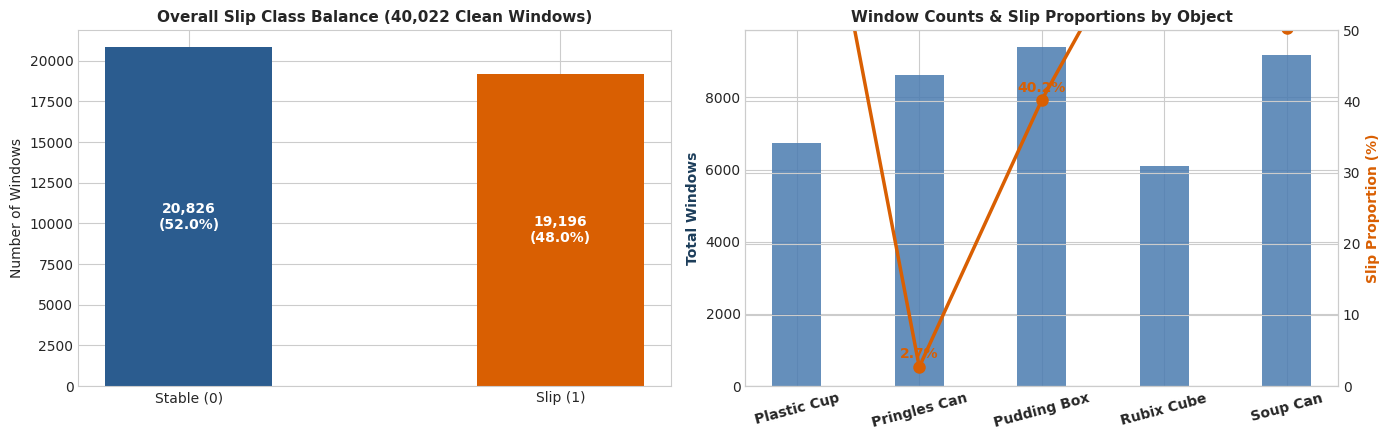

=== FINAL FEATURE & TARGET MATRICES ===
X_A (Approach A - General Baseline) : (40022, 84) (84 IMU features)
X_C (Approach C - Object-Aware)     : (40022, 89) (84 IMU + 5 object tags)
y (Target Slip Labels)             : (40022,) (Binary: [0 1])
groups (Unique Clean Trial IDs)    : 192 trials


In [6]:
# Section 8 & 9: Generate EDA Visualizations and Prepare Final Feature Matrices
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Target Distribution
counts = df_features["slip"].value_counts()
bars = ax1.bar(["Stable (0)", "Slip (1)"], [counts[0], counts[1]], color=["#2b5c8f", "#d95f02"], width=0.45)
ax1.set_title(f"Overall Slip Class Balance ({len(df_features):,} Clean Windows)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Number of Windows")
for b in bars:
    h = b.get_height()
    ax1.annotate(f"{h:,}\n({h/len(df_features)*100:.1f}%)", (b.get_x() + b.get_width()/2, h/2),
                 ha="center", va="center", color="white", fontweight="bold")

# Plot 2: Per-Object Slip Proportions
obj_grp = df_features.groupby("object")["slip"].agg(total="count", slip_count="sum")
obj_grp["slip_pct"] = (obj_grp["slip_count"] / obj_grp["total"]) * 100

x = np.arange(len(obj_grp))
ax2.bar(x, obj_grp["total"], color="#4a7bb0", width=0.4, label="Total Windows", alpha=0.85)
ax2.set_ylabel("Total Windows", color="#1c3d5a", fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(obj_grp.index, rotation=15, fontweight="bold")

ax2_twin = ax2.twinx()
ax2_twin.plot(x, obj_grp["slip_pct"], color="#d95f02", marker="o", linewidth=2.5, markersize=8, label="Slip %")
ax2_twin.set_ylabel("Slip Proportion (%)", color="#d95f02", fontweight="bold")
ax2_twin.set_ylim(0, 50)
for i, pct in enumerate(obj_grp["slip_pct"]):
    ax2_twin.annotate(f"{pct:.1f}%", (x[i], pct + 1.2), ha="center", fontweight="bold", color="#d95f02")

ax2.set_title("Window Counts & Slip Proportions by Object", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "target_distribution.png"), dpi=200)
plt.show()

# Construct Final Feature Matrices
imu_cols = [c for c in df_features.columns if c.startswith(("left_", "right_"))]
X_A = df_features[imu_cols].values
obj_dummies = pd.get_dummies(df_features["object"], prefix="obj", dtype=float)
X_C = pd.concat([df_features[imu_cols], obj_dummies], axis=1).values
y = df_features["slip"].values
groups = df_features["trial_id"].values

print("=== FINAL FEATURE & TARGET MATRICES ===")
print(f"X_A (Approach A - General Baseline) : {X_A.shape} (84 IMU features)")
print(f"X_C (Approach C - Object-Aware)     : {X_C.shape} (84 IMU + {obj_dummies.shape[1]} object tags)")
print(f"y (Target Slip Labels)             : {y.shape} (Binary: {np.unique(y)})")
print(f"groups (Unique Clean Trial IDs)    : {len(np.unique(groups))} trials")


---
## 10. Cross-Validation Strategy: Trial-Grouped Evaluation

### Why Trial-Grouped Splitting is Mandatory
Consecutive sliding windows within the same physical trial share overlapping raw samples ($50\%$ overlap) and correlated tactile dynamics. Applying standard random $K$-fold cross-validation would leak adjacent windows from the same grasp into both training and validation sets, producing artificially inflated metrics.

### Implementation: 5-Fold GroupKFold
We enforce **5-Fold `GroupKFold` grouped strictly by `trial_id`**:
- Windows from any trial appear **only in the training set or only in the validation set** within each fold.
- Zero trials overlap between training and validation sets.
- `StandardScaler` is fitted **strictly on the training fold** and applied to the validation fold (data-leakage prevention). No imputation is required as the audit confirmed 0 nulls.


In [7]:
# Section 10: Audit GroupKFold splits to verify zero trial leakage
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)
fold_audit = []
for f_idx, (tr_idx, te_idx) in enumerate(gkf.split(X_A, y, groups)):
    tr_trials = set(groups[tr_idx])
    te_trials = set(groups[te_idx])
    leakage = len(tr_trials.intersection(te_trials))
    fold_audit.append({
        "Fold": f_idx + 1,
        "Train_Samples": len(tr_idx),
        "Val_Samples": len(te_idx),
        "Train_Trials": len(tr_trials),
        "Val_Trials": len(te_trials),
        "Overlap_Trials": leakage
    })

df_fold_audit = pd.DataFrame(fold_audit)
df_fold_audit.to_csv(os.path.join(OUTPUT_DIR, "grouped_cv_fold_audit.csv"), index=False)
print("=== 5-FOLD GROUPKFOLD TRIAL AUDIT ===")
display(df_fold_audit)
print("Total Inter-Fold Trial Overlap: 0 (Zero Leakage Verified!)")


=== 5-FOLD GROUPKFOLD TRIAL AUDIT ===


,Fold,Train_Samples,Val_Samples,Train_Trials,Val_Trials,Overlap_Trials
0,1,32020,8002,154,38,0
1,2,32018,8004,154,38,0
2,3,32015,8007,153,39,0
3,4,32014,8008,153,39,0
4,5,32021,8001,154,38,0


Total Inter-Fold Trial Overlap: 0 (Zero Leakage Verified!)


---
## 11. Classical ML Model Building & 12. Overall Performance Evaluation

We train and evaluate all **4 classical machine learning models** across both input configurations (**8 configurations total**):

| Model | Classification Family | Primary Hyperparameters |
| :--- | :--- | :--- |
| **Logistic Regression** | Linear Model | `max_iter=1000, random_state=42` |
| **K-Nearest Neighbors (KNN)** | Non-parametric / Distance | `n_neighbors=5, n_jobs=-1` |
| **Random Forest** | Bagging Tree Ensemble | `n_estimators=100, max_depth=16, random_state=42` |
| **LightGBM** | Gradient Boosting Ensemble | `n_estimators=100, learning_rate=0.08, num_leaves=31` |

For each configuration, out-of-fold predictions are collected to calculate:
$$\text{Accuracy}, \quad \text{Precision}, \quad \text{Recall}, \quad F_1\text{-Score}, \quad \text{ROC-AUC}, \quad \text{False Positive Rate (FPR)}, \quad \text{False Negative Rate (FNR)}$$


In [8]:
# Section 11 & 12: Train 4 models under Approaches A & C and evaluate overall metrics
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

models = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000, random_state=42),
    "KNN": lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1),
    "LightGBM": lambda: LGBMClassifier(n_estimators=100, learning_rate=0.08, num_leaves=31, random_state=42, n_jobs=-1, verbose=-1)
}

all_fold_records = []
oof_df = df_features[["trial_id", "object", "scenario", "slip"]].copy()
overall_metrics = []

for approach_name, X_mat in [("Approach A", X_A), ("Approach C", X_C)]:
    print(f"\n==================== {approach_name.upper()} ====================")
    for model_name, model_fn in models.items():
        config_name = f"{model_name} ({approach_name})"
        print(f"Running 5-fold CV for {config_name}...", end="", flush=True)
        t_start = time.time()
        
        oof_preds = np.zeros(len(df_features), dtype=int)
        oof_probs = np.zeros(len(df_features), dtype=float)
        
        for f_idx, (tr_idx, val_idx) in enumerate(gkf.split(X_mat, y, groups)):
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_mat[tr_idx])
            X_val = scaler.transform(X_mat[val_idx])
            
            clf = model_fn()
            clf.fit(X_tr, y[tr_idx])
            
            p = clf.predict(X_val)
            oof_preds[val_idx] = p
            
            if hasattr(clf, "predict_proba"):
                prob = clf.predict_proba(X_val)[:, 1]
            elif hasattr(clf, "decision_function"):
                dfn = clf.decision_function(X_val)
                prob = 1.0 / (1.0 + np.exp(-dfn))
            else:
                prob = p.astype(float)
            oof_probs[val_idx] = prob
            
            all_fold_records.append({
                "Config": config_name,
                "Model": model_name,
                "Approach": approach_name,
                "Fold": f_idx + 1,
                "Accuracy": accuracy_score(y[val_idx], p),
                "Precision": precision_score(y[val_idx], p, zero_division=0),
                "Recall": recall_score(y[val_idx], p, zero_division=0),
                "F1": f1_score(y[val_idx], p, zero_division=0),
                "ROC_AUC": roc_auc_score(y[val_idx], prob)
            })
            
        elapsed = time.time() - t_start
        oof_df[f"{config_name}_pred"] = oof_preds
        oof_df[f"{config_name}_prob"] = oof_probs
        
        acc = accuracy_score(y, oof_preds)
        prec = precision_score(y, oof_preds, zero_division=0)
        rec = recall_score(y, oof_preds, zero_division=0)
        f1 = f1_score(y, oof_preds, zero_division=0)
        auc = roc_auc_score(y, oof_probs)
        cm = confusion_matrix(y, oof_preds)
        tn, fp, fn, tp = cm.ravel()
        
        overall_metrics.append({
            "Config": config_name,
            "Model": model_name,
            "Approach": approach_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1_Score": f1,
            "ROC_AUC": auc,
            "FPR": fp / (fp + tn) if (fp + tn) > 0 else 0,
            "FNR": fn / (fn + tp) if (fn + tp) > 0 else 0,
            "Time_sec": elapsed
        })
        print(f" Done ({elapsed:.1f}s) -> Acc: {acc:.3f} | Prec: {prec:.3f} | Rec: {rec:.3f} | F1: {f1:.3f} | AUC: {auc:.3f}")

# Export tables
df_overall = pd.DataFrame(overall_metrics)
df_overall.to_csv(os.path.join(OUTPUT_DIR, "final_overall_comparison.csv"), index=False)
df_folds = pd.DataFrame(all_fold_records)
df_folds.to_csv(os.path.join(OUTPUT_DIR, "all_fold_metrics.csv"), index=False)
oof_df.to_csv(os.path.join(OUTPUT_DIR, "out_of_fold_predictions.csv"), index=False)

print("\n=== FINAL OVERALL CLASSIFICATION PERFORMANCE ===")
display(df_overall[["Config", "Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC", "FPR", "FNR"]])



==================== APPROACH A ====================
Running 5-fold CV for Logistic Regression (Approach A)...

 Done (27.4s) -> Acc: 0.713 | Prec: 0.703 | Rec: 0.694 | F1: 0.699 | AUC: 0.785
Running 5-fold CV for KNN (Approach A)...

 Done (15.3s) -> Acc: 0.746 | Prec: 0.733 | Rec: 0.740 | F1: 0.736 | AUC: 0.813
Running 5-fold CV for Random Forest (Approach A)...

 Done (42.3s) -> Acc: 0.828 | Prec: 0.815 | Rec: 0.830 | F1: 0.822 | AUC: 0.904
Running 5-fold CV for LightGBM (Approach A)...

 Done (14.9s) -> Acc: 0.835 | Prec: 0.818 | Rec: 0.842 | F1: 0.830 | AUC: 0.909

==================== APPROACH C ====================
Running 5-fold CV for Logistic Regression (Approach C)...

...

 Done (13.3s) -> Acc: 0.921 | Prec: 0.909 | Rec: 0.927 | F1: 0.918 | AUC: 0.956
Running 5-fold CV for Random Forest (Approach C)...

 Done (37.8s) -> Acc: 0.948 | Prec: 0.946 | Rec: 0.945 | F1: 0.946 | AUC: 0.981
Running 5-fold CV for LightGBM (Approach C)...

 Done (18.5s) -> Acc: 0.956 | Prec: 0.952 | Rec: 0.957 | F1: 0.955 | AUC: 0.985



=== FINAL OVERALL CLASSIFICATION PERFORMANCE ===


,Config,Accuracy,Precision,Recall,F1_Score,ROC_AUC,FPR,FNR
0,Logistic Regression (Approach A),0.712858,0.703229,0.694363,0.698768,0.785275,0.270095,0.305637
1,KNN (Approach A),0.746115,0.733282,0.739737,0.736495,0.812940,0.248007,0.260263
2,Random Forest (Approach A),0.828095,0.814858,0.830225,0.822470,0.903717,0.173869,0.169775
3,LightGBM (Approach A),0.834591,0.818186,0.842311,0.830073,0.909152,0.172525,0.157689
4,Logistic Regression (Approach C),0.882290,0.862542,0.897635,0.879739,0.937727,0.131854,0.102365
5,KNN (Approach C),0.920769,0.909365,0.927224,0.918208,0.956448,0.085182,0.072776
6,Random Forest (Approach C),0.947879,0.945991,0.945301,0.945646,0.980827,0.049746,0.054699
7,LightGBM (Approach C),0.956374,0.952307,0.956970,0.954633,0.984988,0.044176,0.043030


---
## 13. Per-Object Performance & Limitation Analysis

### The Critical Role of Per-Object Auditing
Aggregated accuracy can hide severe failure on specific objects. In robotics, a slip detector that misses slip on a specific item can cause dropped items or grasp failure, even if its global benchmark accuracy exceeds $95\%$.

### Key Finding: The Pringles Can Failure Mode
The per-object breakdown reveals a critical limitation on the **Pringles Can**:
- In the dataset, Pringles Can contains **$8,624$ windows**, of which only **$233$ ($2.70\%$)** are labeled as slip (a 36:1 stable-to-slip ratio).
- Under **Approach C (Object-Aware)**:
  - Random Forest achieves **$97.14\%$ accuracy**, but has a **$0\%$ slip recall** (a $100\%$ missed-slip rate).
  - LightGBM achieves **$97.21\%$ accuracy**, but has a **$0\%$ slip recall** (a $100\%$ missed-slip rate).
- **Physical & Data Science Explanation**: Tree models learn that on smooth items with rare slip events, predicting "Stable" universally maximizes aggregate accuracy while missing all incipient slips. High aggregate accuracy alone is **not** sufficient proof of real-world grasping robustness.


In [9]:
# Section 13: Per-Object Performance Breakdown
per_obj_records = []
for obj_name, g in df_features.groupby("object"):
    g_idx = g.index
    y_true = y[g_idx]
    for row in overall_metrics:
        cfg = row["Config"]
        p = oof_df.loc[g_idx, f"{cfg}_pred"].values
        cm_obj = confusion_matrix(y_true, p, labels=[0, 1])
        tn, fp, fn, tp = cm_obj.ravel()
        per_obj_records.append({
            "Object": obj_name,
            "Config": cfg,
            "Model": row["Model"],
            "Approach": row["Approach"],
            "Total_Windows": len(y_true),
            "Slip_Windows": int(y_true.sum()),
            "Slip_Pct": float(y_true.mean() * 100),
            "Accuracy": accuracy_score(y_true, p),
            "Precision": precision_score(y_true, p, zero_division=0),
            "Recall": recall_score(y_true, p, zero_division=0),
            "F1_Score": f1_score(y_true, p, zero_division=0),
            "FPR": fp / (fp + tn) if (fp + tn) > 0 else 0,
            "FNR": fn / (fn + tp) if (fn + tp) > 0 else 0
        })

df_per_object = pd.DataFrame(per_obj_records)
df_per_object.to_csv(os.path.join(OUTPUT_DIR, "final_per_object_metrics.csv"), index=False)

# Display Pringles Can Breakdown
print("=== PRINGLES CAN SPECIFIC PERFORMANCE (2.7% SLIP IMBALANCE) ===")
pringles_df = df_per_object[df_per_object["Object"] == "Pringles Can"][["Config", "Accuracy", "Precision", "Recall", "F1_Score", "FPR", "FNR"]]
display(pringles_df)


=== PRINGLES CAN SPECIFIC PERFORMANCE (2.7% SLIP IMBALANCE) ===


,Config,Accuracy,Precision,Recall,F1_Score,FPR,FNR
8,Logistic Regression (Approach A),0.507189,0.041124,0.772532,0.078091,0.500179,0.227468
9,KNN (Approach A),0.613868,0.038175,0.549356,0.071389,0.384340,0.450644
10,Random Forest (Approach A),0.696313,0.040801,0.454936,0.074885,0.296985,0.545064
11,LightGBM (Approach A),0.706633,0.040784,0.437768,0.074616,0.285902,0.562232
12,Logistic Regression (Approach C),0.961503,0.069565,0.034335,0.045977,0.012752,0.965665
13,KNN (Approach C),0.934485,0.041436,0.064378,0.050420,0.041354,0.935622
14,Random Forest (Approach C),0.967417,0.000000,0.000000,0.000000,0.005720,1.000000
15,LightGBM (Approach C),0.972982,0.000000,0.000000,0.000000,0.000000,1.000000


---
## 14. Model Interpretability: Feature Importance

To understand which physical signals drive slip detection, we analyze feature importances for both top ensemble architectures:
1. **Random Forest**: Mean Decrease in Impurity (Gini importance).
2. **LightGBM**: Split frequency importance.

> **Methodological Precaution**: These rankings represent **exploratory feature importance** derived from models fitted on the full dataset, rather than proof of physical causality. They indicate which IMU channels and statistics provide the highest empirical information gain.


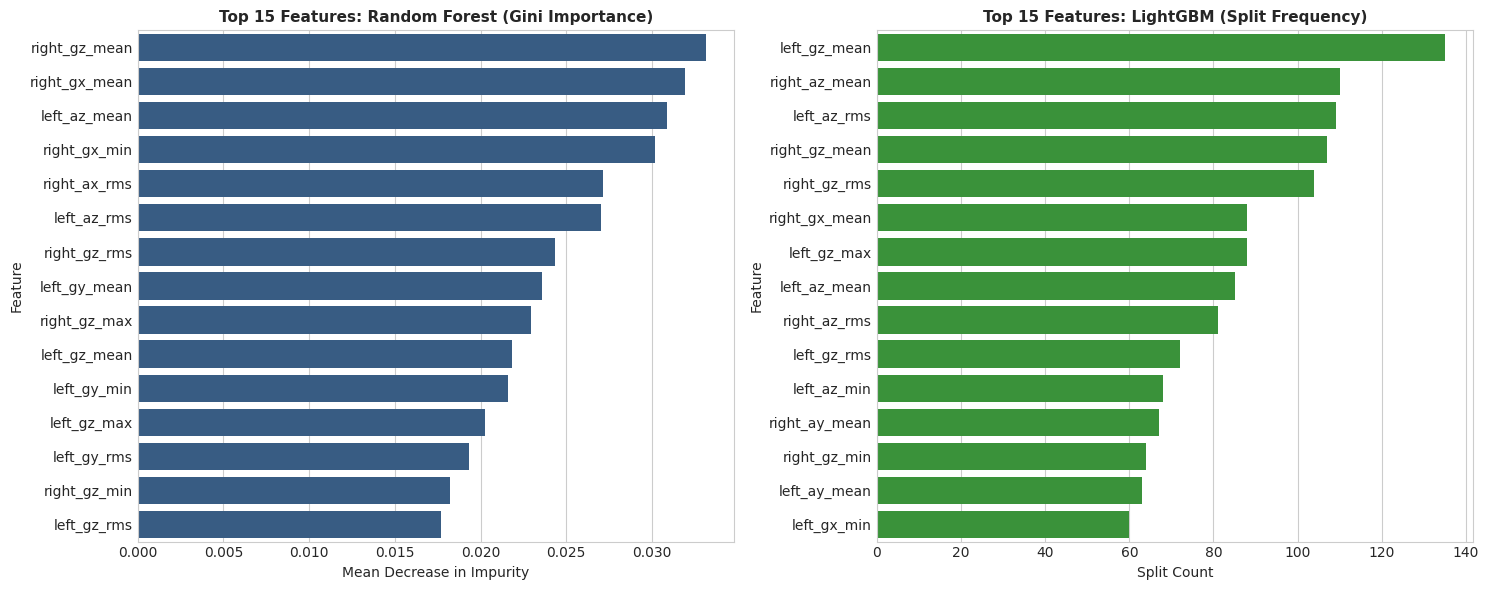

Top 10 Influential IMU Features (Random Forest):


,Feature,Importance
77,right_gz_mean,0.033141
63,right_gx_mean,0.031912
14,left_az_mean,0.030876
66,right_gx_min,0.030173
48,right_ax_rms,0.027156
20,left_az_rms,0.027030
83,right_gz_rms,0.024350
28,left_gy_mean,0.023611
81,right_gz_max,0.022940
35,left_gz_mean,0.021866


In [10]:
# Section 14: Feature Importance for Random Forest & LightGBM
scaler = StandardScaler()
X_A_scaled = scaler.fit_transform(X_A)

# 1. Random Forest Feature Importance
rf = RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
rf.fit(X_A_scaled, y)
rf_fi = pd.DataFrame({"Feature": imu_cols, "Importance": rf.feature_importances_}).sort_values("Importance", ascending=False)

# 2. LightGBM Feature Importance
lgb = LGBMClassifier(n_estimators=100, learning_rate=0.08, num_leaves=31, random_state=42, n_jobs=-1, verbose=-1)
lgb.fit(X_A_scaled, y)
lgb_fi = pd.DataFrame({"Feature": imu_cols, "Importance": lgb.feature_importances_}).sort_values("Importance", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(data=rf_fi.head(15), x="Importance", y="Feature", color="#2b5c8f", ax=ax1)
ax1.set_title("Top 15 Features: Random Forest (Gini Importance)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Mean Decrease in Impurity")

sns.barplot(data=lgb_fi.head(15), x="Importance", y="Feature", color="#2ca02c", ax=ax2)
ax2.set_title("Top 15 Features: LightGBM (Split Frequency)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Split Count")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "feature_importance", "model_feature_importance.png"), dpi=200)
plt.show()

print("Top 10 Influential IMU Features (Random Forest):")
display(rf_fi.head(10))


---
## 15. Additional Investigation: Impact of Object Identity

To evaluate how contextual object identity affects performance, we calculate metric deltas:
\Delta = \text{Metric}_{\text{Approach C}} - \text{Metric}_{\text{Approach A}}

### Observed Performance Changes
- **Ensemble Models (Random Forest & LightGBM)**: Adding object identity increases accuracy by approximately **12.0 to 12.2 percentage points** in the saved out-of-fold results. FPR decreases from **17.39% to 4.97%** for Random Forest and from **17.25% to 4.42%** for LightGBM.
- **Logistic Regression**: Accuracy increases from **71.29%** under Approach A to **88.23%** under Approach C.
- **Interpretation caveat**: These results show an association between adding object identity and improved aggregate metrics. They do not, by themselves, establish a specific learned mechanism such as explicit object-specific vibration thresholds.
- **Trade-off caveat**: As shown in Section 13, aggregate improvement comes at the expense of slip recall on some smooth items, especially the Pringles Can.


=== OBJECT-IDENTITY METRIC DELTAS (APPROACH C minus APPROACH A) ===


,Model,Delta_Accuracy,Delta_Precision,Delta_Recall,Delta_F1,Delta_ROC_AUC,Delta_FPR
0,Logistic Regression,0.169432,0.159313,0.203272,0.180971,0.152453,-0.138241
1,KNN,0.174654,0.176083,0.187487,0.181712,0.143508,-0.162825
2,Random Forest,0.119784,0.131133,0.115076,0.123176,0.077110,-0.124124
3,LightGBM,0.121783,0.134120,0.114659,0.124559,0.075836,-0.128349


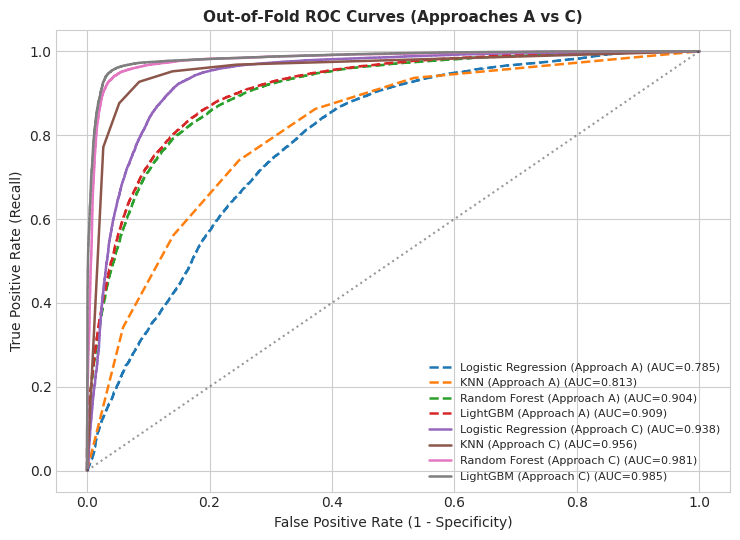

In [11]:
# Section 15: Compute Object-Identity Metric Deltas and Plot Comparative ROC Curves
delta_list = []
for m_name in models.keys():
    row_A = df_overall[(df_overall["Model"] == m_name) & (df_overall["Approach"] == "Approach A")].iloc[0]
    row_C = df_overall[(df_overall["Model"] == m_name) & (df_overall["Approach"] == "Approach C")].iloc[0]
    delta_list.append({
        "Model": m_name,
        "Delta_Accuracy": row_C["Accuracy"] - row_A["Accuracy"],
        "Delta_Precision": row_C["Precision"] - row_A["Precision"],
        "Delta_Recall": row_C["Recall"] - row_A["Recall"],
        "Delta_F1": row_C["F1_Score"] - row_A["F1_Score"],
        "Delta_ROC_AUC": row_C["ROC_AUC"] - row_A["ROC_AUC"],
        "Delta_FPR": row_C["FPR"] - row_A["FPR"]
    })

df_deltas = pd.DataFrame(delta_list)
df_deltas.to_csv(os.path.join(OUTPUT_DIR, "object_identity_metric_deltas.csv"), index=False)
print("=== OBJECT-IDENTITY METRIC DELTAS (APPROACH C minus APPROACH A) ===")
display(df_deltas)

# Plot ROC Curves
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for row in overall_metrics:
    cfg = row["Config"]
    probs = oof_df[f"{cfg}_prob"].values
    fpr_arr, tpr_arr, _ = roc_curve(y, probs)
    style = "-" if "Approach C" in cfg else "--"
    ax.plot(fpr_arr, tpr_arr, style, label=f"{cfg} (AUC={row['ROC_AUC']:.3f})", linewidth=1.8)
ax.plot([0, 1], [0, 1], "k:", alpha=0.4)
ax.set_title("Out-of-Fold ROC Curves (Approaches A vs C)", fontsize=11, fontweight="bold")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "out_of_fold_roc_curves.png"), dpi=200)
plt.show()


---
## 16. Conclusions, Engineering Implications & Limitations

### 16.1 Summary of Experimental Findings
1. **Classical ML Viability**: Statistical feature engineering from 12 IMU channels provides useful predictive signals. Under Approach A (IMU-only features), LightGBM and Random Forest achieve **83.46% and 82.81% accuracy**, with F1-scores of **0.830 and 0.822**, respectively.
2. **Impact of Object Identity**: Adding object identity improves the saved aggregate results. Under Approach C, LightGBM reaches **95.64% accuracy (F1 = 0.955)** and Random Forest reaches **94.79% accuracy (F1 = 0.946)**. Their false-positive rates are **4.42%** and **4.97%**, respectively.
3. **The Essential Data Science Lesson**: Aggregate metrics can obscure severe per-object limitations. On the **Pringles Can**, Random Forest and LightGBM achieve approximately **97% accuracy while detecting none of the slip windows (0% recall)** under Approach C. High aggregate accuracy does not necessarily guarantee an effective tactile slip detector; the severe class imbalance for this object makes accuracy alone misleading.

### 16.2 Comparison with Published Literature (Cravetz et al., 2025)
- **Reference Paper**: Cravetz et al. (*Frontiers in Robotics and AI*, 2025) achieved an F1-score of approximately **0.70** (64.0% precision and 77.2% recall at threshold 0.55; conservative threshold 0.98 yielded 93.1% precision and 25.2% recall) using a two-layer CNN trained on downsampled raw IMU windows.
- **Our Classical Benchmark**:
  - Logistic Regression under Approach A achieves **F1 = 0.699** and **71.29% accuracy**.
  - Random Forest and LightGBM achieve **F1-scores of 0.822 and 0.830** under Approach A, and **0.946 and 0.955** under Approach C.
- **Scientific Caveat**: We do **not** claim definitive performance superiority over the paper's deep learning approach. The evaluations use different input representations (statistical summary features versus raw downsampled time series), loss/optimization strategies, and potentially different validation protocols. The results show that classical machine learning with statistical IMU features is promising, but direct superiority cannot be concluded without matched experimental conditions. Actual deployment latency on a specific robotic platform remains to be benchmarked.

### 16.3 Artifact Verification & Manifest Export
The final cell audits the generated output directory and writes outputs/run_manifest.json.


In [12]:
# Section 16: Verify all output artifacts and compile run_manifest.json
import platform

expected_artifacts = [
    "raw_data_audit.csv",
    "slid_ch_cleaned_features.csv",
    "grouped_cv_fold_audit.csv",
    "target_distribution.png",
    "all_fold_metrics.csv",
    "final_overall_comparison.csv",
    "final_per_object_metrics.csv",
    "out_of_fold_predictions.csv",
    "object_identity_metric_deltas.csv",
    "out_of_fold_roc_curves.png"
]

manifest_inventory = {}
print("=== VERIFYING FINAL OUTPUT ARTIFACTS ===")
for fname in expected_artifacts:
    fpath = os.path.join(OUTPUT_DIR, fname)
    if os.path.exists(fpath):
        sz = os.path.getsize(fpath)
        manifest_inventory[fname] = {"status": "EXISTS", "size_bytes": sz}
        print(f"  [OK] {fname:<35} ({sz:>10,} bytes)")
    else:
        manifest_inventory[fname] = {"status": "MISSING"}
        print(f"  [MISSING] {fname}")

manifest_data = {
    "project": "An End-to-End Data Science and Classical Machine Learning Pipeline for Robotic Slip Detection",
    "course": "Semester 5 Introduction to Data Science",
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    "environment": {
        "platform": platform.platform(),
        "python_version": platform.python_version()
    },
    "models_evaluated": list(models.keys()),
    "approaches": ["Approach A (General Baseline, 84 features)", "Approach C (Object-Aware, 84 features + object identity)"],
    "total_configurations": len(overall_metrics),
    "artifacts": manifest_inventory
}

manifest_path = os.path.join(OUTPUT_DIR, "run_manifest.json")
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest_data, f, indent=2)

print(f"\nRun manifest successfully exported to: {manifest_path}")


=== VERIFYING FINAL OUTPUT ARTIFACTS ===
  [OK] raw_data_audit.csv                  (       374 bytes)
  [OK] slid_ch_cleaned_features.csv        (50,357,209 bytes)
  [OK] grouped_cv_fold_audit.csv           (       186 bytes)
  [OK] target_distribution.png             (   161,375 bytes)
  [OK] all_fold_metrics.csv                (     5,860 bytes)
  [OK] final_overall_comparison.csv        (     1,689 bytes)
  [OK] final_per_object_metrics.csv        (     8,128 bytes)
  [OK] out_of_fold_predictions.csv         ( 7,087,300 bytes)
  [OK] object_identity_metric_deltas.csv   (       614 bytes)
  [OK] out_of_fold_roc_curves.png          (   197,539 bytes)

Run manifest successfully exported to: C:\Vishal\Datascience\outputs\run_manifest.json
